Instruksi 1.2: Mempelajari Driver & Tes Koneksi

In [2]:
from neo4j import GraphDatabase, RoutingControl

URI = "neo4j://localhost:7687"
AUTH = ("neo4j", "adminbesar")

def add_friend(driver, name, friend_name):
    driver.execute_query(
        "MERGE (a:Person {name: $name}) "
        "MERGE (friend:Person {name: $friend_name}) "
        "MERGE (a)-[:KNOWS]->(friend)",
        name=name, friend_name=friend_name, database_="neo4j",
    )

def print_friends(driver, name):
    # Perbaikan minimal: menambah dua underscore (_, _) untuk menampung summary dan keys
    records, _, _ = driver.execute_query(
        "MATCH (a:Person)-[:KNOWS]->(friend) WHERE a.name = $name "
        "RETURN friend.name ORDER BY friend.name",
        name=name, database_="neo4j", routing_=RoutingControl.READ,
    )
    for record in records:
        print(record["friend.name"])

with GraphDatabase.driver(URI, auth=AUTH) as driver:
    add_friend(driver, "Arthur", "Guinevere")
    add_friend(driver, "Arthur", "Lancelot")
    add_friend(driver, "Arthur", "Merlin")
    print("Teman Arthur:")
    print_friends(driver, "Arthur")

Teman Arthur:
Guinevere
Lancelot
Merlin


### Jawaban Pertanyaan Pendahuluan (Checkpoint)
1. **Nama database:** `neo4j` (ditunjukkan oleh parameter `database_="neo4j"` saat memanggil `execute_query`).
2. **Sintaks DDL/DML CYPHER untuk mengakses database lain:**
   - Berpindah database: `USE nama_database;`
   - DDL Admin: `CREATE DATABASE nama_database;`, `SHOW DATABASES;`, `DROP DATABASE nama_database;`.
3. **Jenis graf pertemanan:** *Directed Graph* (Graf Berarah), karena relasi dibentuk dengan arah panah tunggal `(a)-[:KNOWS]->(friend)`[cite: 2].

Instruksi 1.2: CYPHER Total Reset

In [3]:
# Reset/hapus seluruh simpul dan relasi dari tutorial awal sebelum mengimpor data e-commerce
with GraphDatabase.driver(URI, auth=AUTH) as driver:
  driver.execute_query("MATCH (n) DETACH DELETE n;", database_="neo4j")
print("Database Neo4j berhasil dibersihkan (Total Reset).")

Database Neo4j berhasil dibersihkan (Total Reset).


Instruksi 2.1 No. 1 & 2: Wrangling & Filtering Data (Sesuai bagian fold Muhammad Dafa)

In [4]:
import os
import pandas as pd

# Load raw dataset yang diekstrak dari ecommerce-dataset.zip
df = pd.read_csv('data/events.csv')

# Konversi timestamp unix epoch (millisecond) ke datetime
df['datetime'] = pd.to_datetime(df['timestamp'], unit='ms')

# Filter Periode untuk MUHAMMAD DAFA ALVIAN RAMADHANI (sesuai tabel pembagian data UTS)
# Fold Training (P1): 04/05/2015 s.d. 04/07/2015
# Fold Testing (P2) : 13/07/2015 s.d. 28/07/2015
train_start, train_end = '2015-05-04', '2015-07-04'
test_start, test_end = '2015-07-13', '2015-07-28'

df_train = df[
    (df['datetime'] >= train_start) & (df['datetime'] <= train_end)
].copy()
df_test = df[
    (df['datetime'] >= test_start) & (df['datetime'] <= test_end)
].copy()

# Simpan hasil filter ke folder processed_data
os.makedirs('processed_data', exist_ok=True)
df_train.to_csv('processed_data/events_train.csv', index=False)
df_test.to_csv('processed_data/events_test.csv', index=False)

print(
    f'P1 Training Data: {len(df_train)} baris | Visitor Unik:'
    f' {df_train["visitorid"].nunique()} | Item Unik:'
    f' {df_train["itemid"].nunique()}'
)
print(
    f'P2 Testing Data : {len(df_test)} baris | Visitor Unik:'
    f' {df_test["visitorid"].nunique()} | Item Unik:'
    f' {df_test["itemid"].nunique()}'
)

P1 Training Data: 1250321 baris | Visitor Unik: 630720 | Item Unik: 166214
P2 Testing Data : 356242 baris | Visitor Unik: 197158 | Item Unik: 87738


Instruksi 1.3 & 2.1 No. 3: Impor Batch Data Training (P1) ke Neo4j

In [5]:
from tqdm import tqdm


def import_batch(tx, batch):
  cypher_query = """
    UNWIND $batch AS row
    MERGE (v:Visitor {visitorid: row.visitorid})
    MERGE (i:Item {itemid: row.itemid})
    WITH v, i, row
    CALL {
        WITH v, i, row
        WITH v, i, row WHERE row.event = 'view'
        MERGE (v)-[:VIEWED {timestamp: row.timestamp}]->(i)
        UNION ALL
        WITH v, i, row
        WITH v, i, row WHERE row.event = 'addtocart'
        MERGE (v)-[:ADDED_TO_CART {timestamp: row.timestamp}]->(i)
        UNION ALL
        WITH v, i, row
        WITH v, i, row WHERE row.event = 'transaction'
        MERGE (v)-[:BOUGHT {timestamp: row.timestamp, transactionid: row.transactionid}]->(i)
    }
    """
  tx.run(cypher_query, batch=batch)


driver = GraphDatabase.driver(URI, auth=AUTH)
batch_size = 5000

with driver.session() as session:
  # Buat constraint agar proses MERGE berjalan cepat
  session.run(
      'CREATE CONSTRAINT IF NOT EXISTS FOR (v:Visitor) REQUIRE v.visitorid IS'
      ' UNIQUE'
  )
  session.run(
      'CREATE CONSTRAINT IF NOT EXISTS FOR (i:Item) REQUIRE i.itemid IS'
      ' UNIQUE'
  )

  chunks = pd.read_csv('processed_data/events_train.csv', chunksize=batch_size)
  total_rows = len(df_train)
  total_chunks = (total_rows // batch_size) + 1

  print('Memulai proses impor batch data P1 ke Neo4j...')
  for chunk in tqdm(chunks, total=total_chunks, desc='Mengimpor Batch'):
    chunk['transactionid'] = chunk['transactionid'].fillna('').astype(str)
    records = chunk.to_dict(orient='records')
    session.execute_write(import_batch, records)

print('Proses impor data P1 ke Neo4j berhasil diselesaikan.')

Memulai proses impor batch data P1 ke Neo4j...


Mengimpor Batch: 100%|██████████| 251/251 [01:36<00:00,  2.60it/s]

Proses impor data P1 ke Neo4j berhasil diselesaikan.


Instruksi 2.1 No. 3: Query Komposisi Subgraph dengan Python API

In [6]:
with driver.session() as session:
  # Query untuk menghitung jumlah masing-masing jenis simpul
  nodes_result = session.run(
      'MATCH (n) RETURN labels(n)[0] AS Label, count(n) AS Total'
  )
  print('=== Komposisi Simpul (Nodes) ===')
  for record in nodes_result:
    print(f"Jenis Simpul: {record['Label']} | Jumlah: {record['Total']}")

  # Query untuk menghitung jumlah masing-masing jenis relasi
  rels_result = session.run(
      'MATCH ()-[r]->() RETURN type(r) AS Tipe_Relasi, count(r) AS Total'
  )
  print('\n=== Komposisi Relasi (Relationships) ===')
  for record in rels_result:
    print(f"Jenis Relasi: {record['Tipe_Relasi']} | Jumlah: {record['Total']}")

=== Komposisi Simpul (Nodes) ===
Jenis Simpul: Visitor | Jumlah: 630720
Jenis Simpul: Item | Jumlah: 166214

=== Komposisi Relasi (Relationships) ===
Jenis Relasi: VIEWED | Jumlah: 1209600
Jenis Relasi: ADDED_TO_CART | Jumlah: 30484
Jenis Relasi: BOUGHT | Jumlah: 10076


Instruksi 2.1 No. 4: Vector Space Modelling (User) & Plot NetworkX

Karakteristik VSM User:
- Dimensi / Shape: (630720, 166214) (Jumlah Visitor Unik x Jumlah Item Unik)


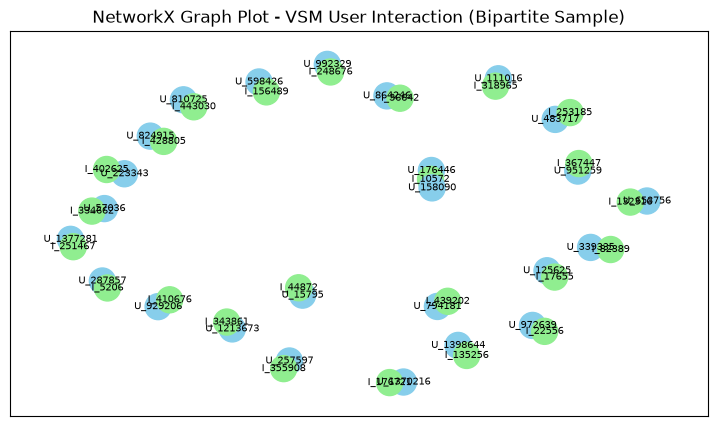

In [7]:
import matplotlib.pyplot as plt
import networkx as nx
from scipy.sparse import csr_matrix

# Ambil interaksi unik Visitor - Item dari data training
interactions = df_train[['visitorid', 'itemid']].drop_duplicates()

visitor_ids = interactions['visitorid'].unique()
item_ids = interactions['itemid'].unique()

visitor_to_idx = {v: i for i, v in enumerate(visitor_ids)}
item_to_idx = {item: i for i, item in enumerate(item_ids)}

rows = interactions['visitorid'].map(visitor_to_idx)
cols = interactions['itemid'].map(item_to_idx)

# Matriks VSM User (Bipartite: User x Item)
vsm_user = csr_matrix(
    ([1] * len(interactions), (rows, cols)),
    shape=(len(visitor_ids), len(item_ids)),
)

print(f'Karakteristik VSM User:')
print(
    f'- Dimensi / Shape: {vsm_user.shape} (Jumlah Visitor Unik x Jumlah Item'
    ' Unik)'
)

# Plot NetworkX untuk sampel 25 interaksi pertama
G_user = nx.Graph()
for _, row in interactions.head(25).iterrows():
  G_user.add_node(f"U_{row['visitorid']}", color='skyblue')
  G_user.add_node(f"I_{row['itemid']}", color='lightgreen')
  G_user.add_edge(f"U_{row['visitorid']}", f"I_{row['itemid']}")

colors = [node[1] for node in G_user.nodes(data='color')]
plt.figure(figsize=(9, 5))
nx.draw_networkx(
    G_user, node_color=colors, with_labels=True, node_size=350, font_size=7
)
plt.title('NetworkX Graph Plot - VSM User Interaction (Bipartite Sample)')
plt.show()

Instruksi 2.1 No. 5: Vector Space Modelling (Item)

In [8]:
# VSM Item merupakan Transpose dari VSM User (Item x User)
vsm_item = vsm_user.T

print(f'Karakteristik VSM Item:')
print(
    f'- Dimensi / Shape: {vsm_item.shape} (Jumlah Item Unik x Jumlah Visitor'
    ' Unik)'
)

Karakteristik VSM Item:
- Dimensi / Shape: (166214, 630720) (Jumlah Item Unik x Jumlah Visitor Unik)


Instruksi 2.1 No. 6: Analisis Proyeksi Terbaik

### Proyeksi Manakah yang Lebih Baik? (Efektif & Efisien)

Berdasarkan eksplorasi VSM User dan VSM Item di atas, **Proyeksi Item (Item-Item Projection)** jauh lebih **efektif dan efisien**.

**Alasan / Uraian:**
1. **Efisiensi Komputasi (Sparsity):** Pada dataset e-commerce Retail Rocket, jumlah *visitor* (user) sangat masif namun mayoritas hanya berinteraksi dengan 1–2 item saja (*very sparse*). Jika menggunakan proyeksi User-User, ukuran matriks kemiripan akan berukuran sangat besar ($N_{visitor} \times N_{visitor}$) dan didominasi nilai nol.
2. **Efektivitas Rekomendasi:** Jumlah *item* lebih stabil dan berumur panjang dibanding *visitor* anonim. Mengukur kemiripan antar-item (*co-occurrence* dari item yang sering diakses bersamaan) menghasilkan pola keterhubungan yang jauh lebih padat (*denser*) dan informatif untuk dijadikan acuan rekomendasi produk.

Instruksi 2.1 No. 7 & 7(a): Perhitungan Cosine Similarity & Query CYPHER Top 5

In [9]:
import numpy as np
from sklearn.metrics.pairwise import cosine_similarity

# Menghitung Cosine Similarity untuk sampel 1000 item pertama agar efisien
sample_size = min(1000, vsm_item.shape[0])
sim_matrix = cosine_similarity(vsm_item[:sample_size])

# Menentukan 1 record item acuan (Index 0)
target_idx = 0
target_item_id = item_ids[target_idx]

# Mengambil 5 item dengan similarity tertinggi (mengabaikan indeks 0 / diri sendiri)
top_5_indices = np.argsort(sim_matrix[target_idx])[::-1][1:6]

similarity_records = [
    {
        'item1': int(target_item_id),
        'item2': int(item_ids[idx]),
        'score': float(sim_matrix[target_idx][idx]),
    }
    for idx in top_5_indices
]

print(f'Record Item Acuan (Item ID): {target_item_id}')
print('Top 5 Record Item Ter-similar:')
for rec in similarity_records:
  print(f"- Item: {rec['item2']} | Cosine Similarity Score: {rec['score']:.4f}")

# (a) CYPHER SQL untuk mendapatkan 5 records dengan similarity tertinggi dari item acuan
cypher_top_5 = f"""
MATCH (i1:Item {{itemid: {target_item_id}}})-[r:SIMILAR]->(i2:Item)
RETURN i1.itemid AS Item_Acuan, i2.itemid AS Item_Similar, r.score AS Similarity_Score
ORDER BY r.score DESC LIMIT 5
"""

print('\nCYPHER SQL Query (7a):')
print(cypher_top_5)

Record Item Acuan (Item ID): 355908
Top 5 Record Item Ter-similar:
- Item: 386527 | Cosine Similarity Score: 0.1204
- Item: 296561 | Cosine Similarity Score: 0.0643
- Item: 308985 | Cosine Similarity Score: 0.0602
- Item: 466501 | Cosine Similarity Score: 0.0557
- Item: 248676 | Cosine Similarity Score: 0.0538

CYPHER SQL Query (7a):

MATCH (i1:Item {itemid: 355908})-[r:SIMILAR]->(i2:Item)
RETURN i1.itemid AS Item_Acuan, i2.itemid AS Item_Similar, r.score AS Similarity_Score
ORDER BY r.score DESC LIMIT 5



Instruksi 2.1 No. 7(b): Write-back Nilai Similarity ke Graf & Perlihatkan Query-nya

In [10]:
# Query untuk menuliskan (write-back) relasi SIMILAR ke database Neo4j
write_cypher = """
UNWIND $batch AS row
MATCH (i1:Item {itemid: row.item1})
MATCH (i2:Item {itemid: row.item2})
MERGE (i1)-[r:SIMILAR {score: row.score}]->(i2)
"""

with driver.session() as session:
  # Tulis nilai similarity ke graf
  session.execute_write(
      lambda tx: tx.run(write_cypher, batch=similarity_records)
  )
  print('Berhasil menuliskan relasi [:SIMILAR] ke graf Neo4j.\n')

  # Jalankan query CYPHER untuk memperlihatkan hasilnya dari graf
  result = session.run(cypher_top_5)
  print('=== Hasil Query Cypher dari Database Neo4j ===')
  for record in result:
    print(
        f"Item Acuan: {record['Item_Acuan']} -> Item Similar:"
        f" {record['Item_Similar']} | Score: {record['Similarity_Score']:.4f}"
    )

Berhasil menuliskan relasi [:SIMILAR] ke graf Neo4j.

=== Hasil Query Cypher dari Database Neo4j ===
Item Acuan: 355908 -> Item Similar: 386527 | Score: 0.1204
Item Acuan: 355908 -> Item Similar: 296561 | Score: 0.0643
Item Acuan: 355908 -> Item Similar: 308985 | Score: 0.0602
Item Acuan: 355908 -> Item Similar: 466501 | Score: 0.0557
Item Acuan: 355908 -> Item Similar: 248676 | Score: 0.0538


Instruksi 2.1 No. 8: CYPHER SQL Kondisi Sebelum dan Sesudah Perhitungan Similarity

### Kondisi Sebelum dan Sesudah Perhitungan Similarity

**1. Kondisi Sebelum (Hanya berdasarkan interaksi implisit User-Item):**
```cypher
MATCH (i1:Item {itemid: 12345})<-[:VIEWED]-(v:Visitor)-[:VIEWED]->(i2:Item)
RETURN i1.itemid, v.visitorid, i2.itemid LIMIT 5
```
**2. Kondisi Sesudah menggunakan relasi eksplisit :SIMILAR hasil perhitungan VSM:**
```cypher
MATCH (i1:Item {itemid: 12345})-[r:SIMILAR]->(i2:Item)
RETURN i1.itemid AS Item_Acuan, i2.itemid AS Item_Rekomendasi, r.score AS Similarity_Score
ORDER BY r.score DESC LIMIT 5
```

Instruksi 2.2 No. 1(a) Analytics KNN Recommendation & 1(b) 3 item yang diiklankan untuk k = 5 pada penentuan KNN

In [14]:
import random
import numpy as np

# PEMILIHAN USER SECARA ACAK & REPRODUSIBEL (SEED = 42)
# Ambil irisan Visitor ID yang aktif di Train (P1) dan Test (P2)
common_visitors = list(set(df_train['visitorid']).intersection(set(df_test['visitorid'])))

# Filter visitor yang minimal salah satu itemnya ada dalam jangkauan sample_size
valid_visitors = [
    v for v in common_visitors 
    if any(item in item_to_idx and item_to_idx[item] < sample_size 
           for item in df_train[df_train['visitorid'] == v]['itemid'].unique())
]

SEED = 42
random.seed(SEED)
target_user = random.choice(valid_visitors)

print(f"User terpilih secara acak (Seed={SEED}): {target_user}\n")

# (a) SKRIP PYTHON REKOMENDASI KNN
def get_knn_recommendations(user_id, k=5, top_n=3):
    user_history = set(df_train[df_train['visitorid'] == user_id]['itemid'].unique())
    candidate_scores = {}
    
    for item in user_history:
        if item in item_to_idx and item_to_idx[item] < sample_size:
            idx = item_to_idx[item]
            scores = sim_matrix[idx]
            top_k_idx = np.argsort(scores)[::-1][1:k+1]
            
            for n_idx in top_k_idx:
                candidate_item = item_ids[n_idx]
                if candidate_item not in user_history:
                    candidate_scores[candidate_item] = candidate_scores.get(candidate_item, 0) + scores[n_idx]
                    
    recommended = sorted(candidate_scores.items(), key=lambda x: x[1], reverse=True)[:top_n]
    return [item for item, score in recommended]

# (b) 3 ITEM YANG DIIKLANKAN / DIREKOMENDASIKAN UNTUK k = 5
rec_3_items = get_knn_recommendations(target_user, k=5, top_n=3)

print("=== HASIL REKOMENDASI SOAL 2.2 NO. 1 ===")
print(f"(a) Fungsi KNN Recommendation berhasil disiapkan.")
print(f"(b) 3 Item yang diiklankan untuk k=5: {rec_3_items}")

User terpilih secara acak (Seed=42): 629333

=== HASIL REKOMENDASI SOAL 2.2 NO. 1 ===
(a) Fungsi KNN Recommendation berhasil disiapkan.
(b) 3 Item yang diiklankan untuk k=5: [np.int64(251467), np.int64(304685), np.int64(355908)]


Instruksi 2.2 No. 2: Evaluasi Metrik Hit@5 dan NDCG@5

In [15]:
# Ground Truth: Item aktual yang diinteraksikan user pada periode testing (P2)
actual_p2_items = set(
    df_test[df_test['visitorid'] == target_user]['itemid'].unique()
)

# Ambil Top 5 item rekomendasi (K=5)
rec_5_items = get_knn_recommendations(target_user, k=5, top_n=5)


# (a) Hitung Hit@5
def calculate_hit_at_k(recommended, actual):
  return 1 if any(item in actual for item in recommended) else 0


# (b) Hitung NDCG@5
def calculate_ndcg_at_k(recommended, actual):
  dcg = sum(
      1.0 / np.log2(i + 2)
      for i, item in enumerate(recommended)
      if item in actual
  )
  idcg = sum(
      1.0 / np.log2(i + 2) for i in range(min(len(actual), len(recommended)))
  )
  return dcg / idcg if idcg > 0 else 0.0


hit_5 = calculate_hit_at_k(rec_5_items, actual_p2_items)
ndcg_5 = calculate_ndcg_at_k(rec_5_items, actual_p2_items)

print(f'Ground Truth Item di Periode P2: {actual_p2_items}')
print(f'Top 5 Item Rekomendasi          : {rec_5_items}')
print(f'Hit@5                           : {hit_5}')
print(f'NDCG@5                          : {ndcg_5:.4f}')

Ground Truth Item di Periode P2: {np.int64(452896)}
Top 5 Item Rekomendasi          : [np.int64(251467), np.int64(304685), np.int64(355908), np.int64(457402), np.int64(152348)]
Hit@5                           : 0
NDCG@5                          : 0.0000
